# **Part FOUR: Managing Data and Table Operations**
**Duration: 45 mins**
* DROP TABLE
* SELECT Example Without DISTINCT
* SELECT DISTINCT
* Count Distinct

## **Additional Topics in SQL for the learners to go through on thier own**
[link](https://colab.research.google.com/drive/1lpl4RSknXOOBkPvMFwSeW0BEiFZUTM-i?usp=sharing)
* SQL AND, OR Operators
* SQL NOT Operator, NOT LIKE, NOT BETWEEN, NOT IN, NOT Greater Than, NOT Less Than.



## **DROP TABLE**
**What is DROP TABLE?**

**What it Does:**
* DROP TABLE is an SQL command used to delete an entire table from the database.Deletes a table permanently, including its structure and data

**It removes:**
* All the data in the table.
* The table’s structure (columns, keys, etc.).
* The table will no longer exist after running this command.

**When to Use DROP TABLE**

**When to Use:**
* You no longer need the table or its data.
* You are cleaning up old, unused tables to reduce clutter in the database.

**When NOT to Use:**
* You still need the data in the table.
* You want to delete only specific rows of data (use DELETE instead).
Other tables depend on this table, and deleting it may break relationships.

**Step 1: Connect to the Database**


In [ ]:
import sqlite3

connection = sqlite3.connect('school.db')

print('Create DB School successfully')

Create DB School successfully


**Step 2: Create a Cursor Object**

In [ ]:
Cursor = connection.cursor()
print('Cursor created successfully')

Cursor created successfully


**Step 3: Write and Execute the DROP TABLE Command**

In [ ]:
Cursor.execute('DROP TABLE IF EXISTS School')
print('School Table Drop')

School Table Drop


**Step 4: Commit the Changes**


In [ ]:
connection.commit()
print('Print To Changes')

Print To Changes


**Step 5: Close the Connection**




In [ ]:
connection.close()
print('Connection Close')

Connection Close


## **SELECT Example Without DISTINCT**
**What it Does:**
* The SELECT statement retrieves data from the table.
* By default, SELECT will return all rows, including duplicates.

Scenario:
You have a Users table for an online platform, and it looks like this
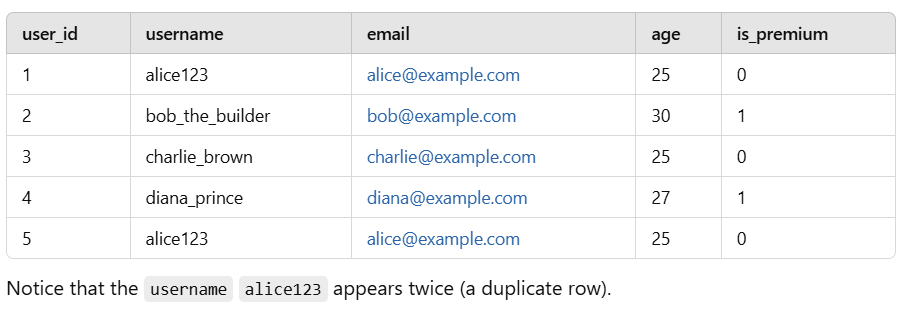

**When to Use:**

Use SELECT without DISTINCT when you want to retrieve all rows, even if some data is repeated.

**When NOT to Use:**

Don’t use SELECT without DISTINCT if you need unique results or want to avoid duplicates in the output.

In [ ]:
import sqlite3

# Step 1: Connect to the database
connection = sqlite3.connect("users.db")
cursor = connection.cursor()

cursor.execute('DROP TABLE IF EXISTS Users')

# Step 2: Create the Users table
cursor.execute("""
CREATE TABLE IF NOT EXISTS Users (
    user_id INTEGER ,
    username TEXT,
    email TEXT,
    phone_number TEXT,
    age INTEGER,
    is_premium INTEGER
);
""")

# Step 3: Insert data into the Users table
cursor.executemany("""
INSERT INTO Users (user_id, username, email, phone_number, age, is_premium)
VALUES (?, ?, ?, ?,?,?);
""", [
    (1, 'alice123', 'alice@example.com', '9876543210',25, 0),
    (2, 'bob_the_builder', 'bob@example.com', None, 30, 1),  # NULL phone_number
    (3, 'charlie_brown', 'charlie@example.com', None, 22, 0),  # NULL phone_number
    (4, 'diana_prince', 'diana@example.com', '9123456789', 27, 1),
    (5, 'eve_hacker', 'eve@example.com', '9988776655', 30, 0),
    (6, 'alice123', 'alice@example.com', '9876543210',25, 0)
])

# Step 4: Commit changes and close the connection
connection.commit()

print("Users table created successfully with data!")

# Step 7: Close connection
connection.close()

Users table created successfully with data!


In [28]:
import sqlite3

# Step 1: Connect to the database
connection = sqlite3.connect("users.db")
cursor = connection.cursor()

# Step: Execute SELECT query without DISTINCT
cursor.execute("SELECT username FROM Users;")
rows = cursor.fetchall()

# Display the results
print("All usernames (including duplicates):")
for row in rows:
  print(row[0])

connection.close()

All usernames (including duplicates):
alice123
bob_the_builder
charlie_brown
diana_prince
eve_hacker
alice123


In [19]:
import sqlite3
from tabulate import tabulate

connection = sqlite3.connect('users.db')
cursor = connection.cursor()

# Execute SELECT query without DISTINCT
cursor.execute('SELECT username FROM Users')

## Fetch all rows
row = cursor.fetchall()

# Get column name
column_names = [column[0] for column in cursor.description]

# Display the results in table format
print("All usernames (including duplicates):")

print(tabulate(row, headers=column_names, tablefmt='grid'))

# Close the connection
connection.close()

All usernames (including duplicates):
+-----------------+
| username        |
+=================+
| alice123        |
+-----------------+
| bob_the_builder |
+-----------------+
| charlie_brown   |
+-----------------+
| diana_prince    |
+-----------------+
| eve_hacker      |
+-----------------+
| alice123        |
+-----------------+


## **SELECT DISTINCT**
**What it Does:**
* The SELECT DISTINCT statement retrieves only unique values from a column or set of columns.
* It removes duplicate rows from the result.

Scenario:
Let’s say you want to retrieve the unique usernames from the Users table.

**When to Use:**

Use SELECT DISTINCT when:
* You only need unique values.
* You want to avoid duplicates in the result.

**When NOT to Use:**

Don’t use DISTINCT if you want to include duplicates in your results (e.g., to count how often a value appears).

In [21]:
import sqlite3

connection = sqlite3.connect('users.db')
cursor = connection.cursor()

# # Execute SELECT DISTINCT query
cursor.execute('SELECT DISTINCT username FROM Users')
row = cursor.fetchall()

# Display the results
print("Unique usernames (no duplicates):")
for r in row:
  print(r[0]) # Print only the username

connection.close()

Unique usernames (no duplicates):
alice123
bob_the_builder
charlie_brown
diana_prince
eve_hacker


The duplicate alice123 is removed, and only unique usernames are returned.

## **Count Distinct**

**What it Does:**

The COUNT(DISTINCT column_name) function counts the number of unique values in a specific column.

Scenario:
You want to count the number of unique ages in the Users table.

In [30]:
import sqlite3

connection = sqlite3.connect('users.db')
cursor = connection.cursor()

#execute sql query
cursor.execute('SELECT COUNT(DISTINCT age) FROM Users')
row = cursor.fetchone()

# Display the result
print(f"Number of unique ages: {row[0]}")

connection.close()

Number of unique ages: 4


There are 4 unique ages in the Users table: 22, 25, 30, and 27.

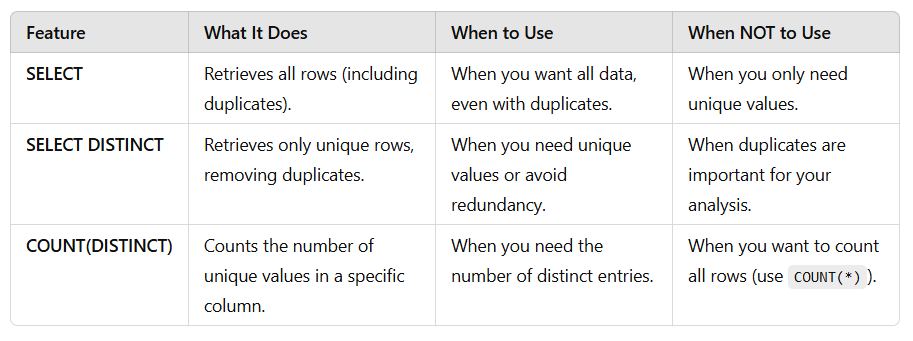


## **SQLite Fetch Functions Comparison**

| Feature | fetchone() | fetchmany() | fetchall() |
|---|---|---|---|
| Records | 1 | As needed | All remaining |
| Return Type | Tuple | List of Tuples | List of Tuples |
| Use | Single record | Limited records | All records |
| Memory Usage | Low | Moderate | Can be high |



## **SQLite Fetch Functions – Quick Revision Table**

| Function | Meaning | Example | Output |
|---|---|---|---|
| `fetchone()` | एक record निकालना | `cursor.fetchone()` | 1 Row |
| `fetchmany()` | कुछ records निकालना | `cursor.fetchmany(3)` | 3 Rows |
| `fetchall()` | सभी records निकालना | `cursor.fetchall()` | All Rows |


# **Part FIVE:Managing NULLs and Aggregates**
**Duration: 45 mins**
* NULL Values
* SQL Aggregate Functions

## **NULL Values**
What Are NULL Values?
* NULL means a column has no value or no data.
* It’s different from 0 (a number) or an empty string '' (text).
Example: If a user hasn’t provided their phone number, the value in the phone_number column will be NULL.



**create a user table**

In [7]:
import sqlite3

# Step 1: Connect to the database
connection = sqlite3.connect('e-commerce.db')
cursor = connection.cursor()

# Step 2: Create the Users table
cursor.execute("""
CREATE TABLE IF NOT EXISTS Users (
        user_id INTEGER PRIMARY KEY,
        username TEXT,
        email TEXT,
        phone_number TEXT,
        age INTEGER,
        is_premium INTEGER
    );
""")

# Step 3 : Insert data into the Users table

cursor.executemany("""
INSERT INTO Users (user_id, username, email, phone_number, age, is_premium)
    VALUES (?,?,?,?,?,?);
""", [
    (1, 'alice123', 'alice@example.com', '9876543210',25, 0),
    (2, 'bob_the_builder', 'bob@example.com', None, 30, 1),  # NULL phone_number
    (3, 'charlie_brown', 'charlie@example.com', None, 22, 0),  # NULL phone_number
    (4, 'diana_prince', 'diana@example.com', '9123456789', 27, 1),
    (5, 'eve_hacker', 'eve@example.com', '9988776655', 30, 0)
])

# Step 4: Commit changes and close the connection
connection.commit()
connection.close()

print("Users table created successfully with data!")

Users table created successfully with data!


1.CREATE TABLE: This command is used to create a new table in the database.

2.IF NOT EXISTS: This clause ensures that the table will only be created if it does not already exist in the database.
* If a table named Users already exists, the statement will do nothing.
* If the table does not exist, the command will create it.

Insert Data:

* executemany: Inserts multiple rows of data into the Users table.
* None: Used to represent NULL values in Python.

## **IS NULL Operator**

**What It Does**
* IS NULL checks for rows where a column has no value (NULL).
* It filters out rows where the column has data.

**When to Use**

Use IS NULL when you need to find rows where no data is provided in a specific column

**When NOT to Use**

Don’t use IS NULL if you’re searching for rows where a column has a specific value (use = for that).

Example: Find users who haven’t provided their phone numbers

In [10]:
import sqlite3

# Connect to the database
connection = sqlite3.connect('e-commerce.db')
cursor = connection.cursor()

# Find users with NULL phone numbers
cursor.execute("SELECT * FROM Users WHERE phone_number IS NULL;")
rows = cursor.fetchall()

print("Users who haven't provided their phone numbers:")
for row in rows:
  print(row)

connection.commit()

connection.close()



Users who haven't provided their phone numbers:
(2, 'bob_the_builder', 'bob@example.com', None, 30, 1)
(3, 'charlie_brown', 'charlie@example.com', None, 22, 0)


## **IS NOT NULL Operator**
**What It Does**
* IS NOT NULL checks for rows where a column has a value (not NULL).
* It filters out rows where the column is empty.

**When to Use**
* Use IS NOT NULL when you need to find rows where data exists in a specific
column.

**When NOT to Use**

* Don’t use IS NOT NULL if you’re searching for rows that have no data (use IS NULL for that).

Example: Find users who have provided their phone numbers

In [11]:
import sqlite3

connection = sqlite3.connect('e-commerce.db')
cursor = connection.cursor()

cursor.execute(" SELECT * FROM Users WHERE phone_number IS NOT NULL;")
rows = cursor.fetchall()

print("Users who have provided their phone numbers:")
for row in rows:
  print(row)

# Commit changes and close the connection
connection.commit()
connection.close()

Users who have provided their phone numbers:
(1, 'alice123', 'alice@example.com', '9876543210', 25, 0)
(4, 'diana_prince', 'diana@example.com', '9123456789', 27, 1)
(5, 'eve_hacker', 'eve@example.com', '9988776655', 30, 0)


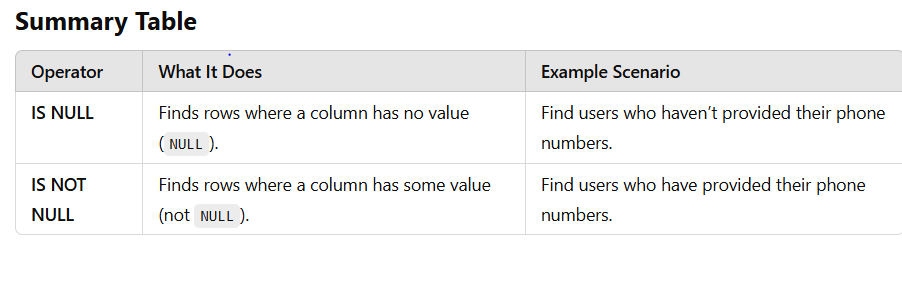

## **SQL Aggregate Functions**

**What Are SQL Aggregate Functions?**

Aggregate functions perform calculations on multiple rows of data and return a single value.

Common aggregate functions include:
* COUNT: Counts the number of rows.
* AVG: Calculates the average value.
* SUM: Adds up numeric values.
* MIN: Finds the smallest value.
* MAX: Finds the largest value.

Lets use the same user table given above

**COUNT**

**What It Does**

* COUNT counts the number of rows in a column or table.
* Use COUNT(*) to count all rows, and COUNT(column_name) to count rows where the column is not NULL.

**When to Use**
To determine how many users, records, or entries exist in the table.

Example: Count the total number of users




In [15]:
import sqlite3

# Connect to the database
connection = sqlite3.connect('e-commerce.db')
cursor = connection.cursor()

## Count total number of users
cursor.execute("SELECT COUNT(*) FROM Users; ")
result = cursor.fetchone()

# Total number of users
print(f"Total number of users: {result[0]}")

# Commit changes and close the connection
connection.commit()
connection.close()

Total number of users: 5


ursor.execute("SELECT COUNT(*) FROM Users;")

1.SELECT

**What It Does:**

* The SELECT keyword is used to fetch data from the database.
* In this query, we’re not fetching data from a specific column but instead performing a calculation using COUNT().

2.COUNT(*)

**What It Does:**

* COUNT(*) is a function that counts the total number of rows in a table.
* The * means "all columns." It tells the database to include every row, regardless of the column values.



**AVG (Average)**

**What It Does**
* AVG calculates the average value of a numeric column (e.g., age).
* Skips rows where the column is NULL.

**When to Use**
* To find average statistics, such as the average age of users.

Example: Find the average age of users

In [18]:
import sqlite3

# Connect to the database
connection = sqlite3.connect('e-commerce.db')
cursor = connection.cursor()

# Sql Query
cursor.execute("SELECT AVG(age) FROM Users;")
result = cursor.fetchone()

print(f"Average age of users: {result[0]:.2f}")

# Commit changes and close the connection
connection.commit()
connection.close()


Average age of users: 26.80


**SUM**

**What It Does**
* SUM adds up all values in a numeric column.
* Skips rows where the column is NULL.

**When to Use**
* To calculate totals, such as the total sum of ages.

Example: Find the total sum of users' ages


In [20]:
import sqlite3

# Connect to the database
connection = sqlite3.connect('e-commerce.db')
cursor = connection.cursor()

#SQL Query
cursor.execute('SELECT SUM(age) FROM Users;')
result = cursor.fetchone()

print(f'Total sum of users ages: {result[0]:.2f}')


Total sum of users ages: 134.00


**MIN**

**What It Does**
* MIN finds the smallest value in a numeric or text column.

**When to Use**
* To identify the youngest user, lowest salary, or earliest date.

Example: Find the youngest user

In [23]:
import sqlite3

# Connect to the database
connection = sqlite3.connect('e-commerce.db')
cursor = connection.cursor()

#SQL Query
cursor.execute('SELECT MIN(age) FROM users;')
result = cursor.fetchone()

print(f'Youngest User age: {result[0]:.2f}')

Youngest User age: 22.00


**MAX**

**What It Does**
* MAX finds the largest value in a numeric or text column.

**When to Use**
* To identify the oldest user, highest salary, or latest date.

Example: Find the oldest user

In [24]:
import sqlite3

# Connect to the database
connection = sqlite3.connect('e-commerce.db')
cursor = connection.cursor()

#SQL Query
cursor.execute('SELECT MAX(age) FROM users;')
result = cursor.fetchone()

print(f'The oldest user age: {result[0]:.2f}')


The oldest user age: 30.00


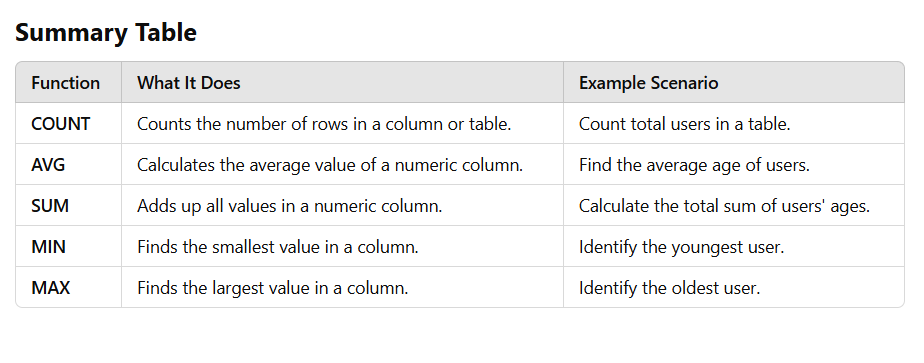